In [12]:
import pandas as pd

df = pd.read_excel("../data/online_retail_II.xlsx", engine="openpyxl")

print("Kích thước dữ liệu:", df.shape)
print("Các cột:", df.columns.tolist())
display(df.head())

Kích thước dữ liệu: (525461, 8)
Các cột: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [13]:
print("Số dòng, số cột:", df.shape)

print("\nTên các cột:")
print(df.columns.tolist())

print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum())

print("\nSố dòng trùng lặp:", df.duplicated().sum())

print("\nKiểu dữ liệu:")
print(df.dtypes)

display(df.head())

Số dòng, số cột: (525461, 8)

Tên các cột:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Số lượng giá trị thiếu:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Số dòng trùng lặp: 6865

Kiểu dữ liệu:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [14]:
print("Thông tin dữ liệu:")
df.info()

print("\nThống kê Quantity và Price:")
display(df[["Quantity", "Price"]].describe())

print("\nSố hóa đơn bắt đầu bằng C:",
      df["Invoice"].astype(str).str.startswith("C").sum())

print("Số dòng Quantity <= 0:",
      (df["Quantity"] <= 0).sum())

print("Số dòng Price <= 0:",
      (df["Price"] <= 0).sum())

print("\nTỷ lệ thiếu (%):")
print((df.isnull().mean() * 100).round(2))

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB

Thống kê Quantity và Price:


,Quantity,Price
count,525461.000000,525461.000000
mean,10.337667,4.688834
std,107.424110,146.126914
min,-9600.000000,-53594.360000
25%,1.000000,1.250000
50%,3.000000,2.100000
75%,10.000000,4.210000
max,19152.000000,25111.090000



Số hóa đơn bắt đầu bằng C: 10206
Số dòng Quantity <= 0: 12326
Số dòng Price <= 0: 3690

Tỷ lệ thiếu (%):
Invoice         0.00
StockCode       0.00
Description     0.56
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    20.54
Country         0.00
dtype: float64


In [15]:
df_clean = df.copy()

print("Số dòng ban đầu:", len(df_clean))

df_clean = df_clean.drop_duplicates()

print("Sau khi xóa dòng trùng:", len(df_clean))

df_clean["Description"] = (
    df_clean["Description"]
    .astype("string")
    .str.strip()
)

df_clean["Customer ID"] = df_clean["Customer ID"].astype("Int64")

print("\nSố dòng còn lại:", len(df_clean))
print("Số dòng trùng còn lại:", df_clean.duplicated().sum())
print("\nGiá trị thiếu:")
print(df_clean.isnull().sum())

Số dòng ban đầu: 525461
Sau khi xóa dòng trùng: 518596

Số dòng còn lại: 518596
Số dòng trùng còn lại: 0

Giá trị thiếu:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107833
Country             0
dtype: int64


In [16]:
cancelled = df_clean["Invoice"].astype(str).str.startswith("C")
print("Số dòng hóa đơn hủy:", cancelled.sum())

print("Số dòng Quantity âm:",
      (df_clean["Quantity"] < 0).sum())
print("Số dòng Quantity bằng 0:",
      (df_clean["Quantity"] == 0).sum())

print("Số dòng Price âm:",
      (df_clean["Price"] < 0).sum())
print("Số dòng Price bằng 0:",
      (df_clean["Price"] == 0).sum())

display(df_clean[df_clean["Quantity"] < 0].head(10))

display(df_clean[df_clean["Price"] <= 0].head(10))

Số dòng hóa đơn hủy: 10182
Số dòng Quantity âm: 12302
Số dòng Quantity bằng 0: 0
Số dòng Price âm: 3
Số dòng Price bằng 0: 3681


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom
3114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom
3161,489659,21350,<NA>,230,2009-12-01 17:39:00,0.0,<NA>,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom
3731,489781,84292,<NA>,17,2009-12-02 11:45:00,0.0,<NA>,United Kingdom
4296,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom


In [17]:
print("Các giao dịch có Price âm:")
display(df_clean[df_clean["Price"] < 0])

print("Một số giao dịch có Price bằng 0:")
display(df_clean[df_clean["Price"] == 0].head(10))

cancelled = df_clean["Invoice"].astype(str).str.startswith("C")
negative_quantity = df_clean["Quantity"] < 0

print(
    "Số dòng vừa là hóa đơn hủy vừa có Quantity âm:",
    (cancelled & negative_quantity).sum()
)
print(
    "Số dòng Quantity âm nhưng không có mã hóa đơn bắt đầu bằng C:",
    (~cancelled & negative_quantity).sum()
)

Các giao dịch có Price âm:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,<NA>,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,<NA>,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,<NA>,United Kingdom


Một số giao dịch có Price bằng 0:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom
3114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom
3161,489659,21350,<NA>,230,2009-12-01 17:39:00,0.0,<NA>,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom
3731,489781,84292,<NA>,17,2009-12-02 11:45:00,0.0,<NA>,United Kingdom
4296,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom


Số dòng vừa là hóa đơn hủy vừa có Quantity âm: 10181
Số dòng Quantity âm nhưng không có mã hóa đơn bắt đầu bằng C: 2121


In [18]:
df_sales = df_clean.copy()

df_sales = df_sales[
    ~df_sales["Invoice"].astype(str).str.startswith("C")
]

df_sales = df_sales[
    (df_sales["Quantity"] > 0) &
    (df_sales["Price"] > 0)
]

df_sales["Revenue"] = (
    df_sales["Quantity"] * df_sales["Price"]
)

print("Số dòng sau khi lọc:", len(df_sales))
print("Số dòng còn Quantity âm:",
      (df_sales["Quantity"] < 0).sum())
print("Số dòng còn Price <= 0:",
      (df_sales["Price"] <= 0).sum())
print("Tổng doanh thu:", round(df_sales["Revenue"].sum(), 2))

display(df_sales.head())

Số dòng sau khi lọc: 504730
Số dòng còn Quantity âm: 0
Số dòng còn Price <= 0: 0
Tổng doanh thu: 10271762.66


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [19]:
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    df_sales.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

print("Doanh thu theo tháng:")
display(monthly_revenue.reset_index())


Doanh thu theo tháng:


,Month,Revenue
0,2009-12,822483.950
1,2010-01,651155.112
2,2010-02,551504.726
3,2010-03,830915.261
4,2010-04,678875.252
5,2010-05,657705.500
6,2010-06,749537.310
7,2010-07,648810.270
8,2010-08,695251.910
9,2010-09,921696.991


In [20]:
top_products = (
    df_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 sản phẩm có doanh thu cao nhất:")
display(top_products.reset_index())

Top 10 sản phẩm có doanh thu cao nhất:


,Description,Revenue
0,Manual,262589.86
1,REGENCY CAKESTAND 3 TIER,169912.76
2,WHITE HANGING HEART T-LIGHT HOLDER,160345.63
3,DOTCOM POSTAGE,116408.71
4,ASSORTED COLOUR BIRD ORNAMENT,72890.19
5,PAPER CHAIN KIT 50'S CHRISTMAS,58127.30
6,JUMBO BAG RED RETROSPOT,56480.46
7,PARTY BUNTING,49664.12
8,POSTAGE,49477.54
9,ROTATING SILVER ANGELS T-LIGHT HLDR,47954.49


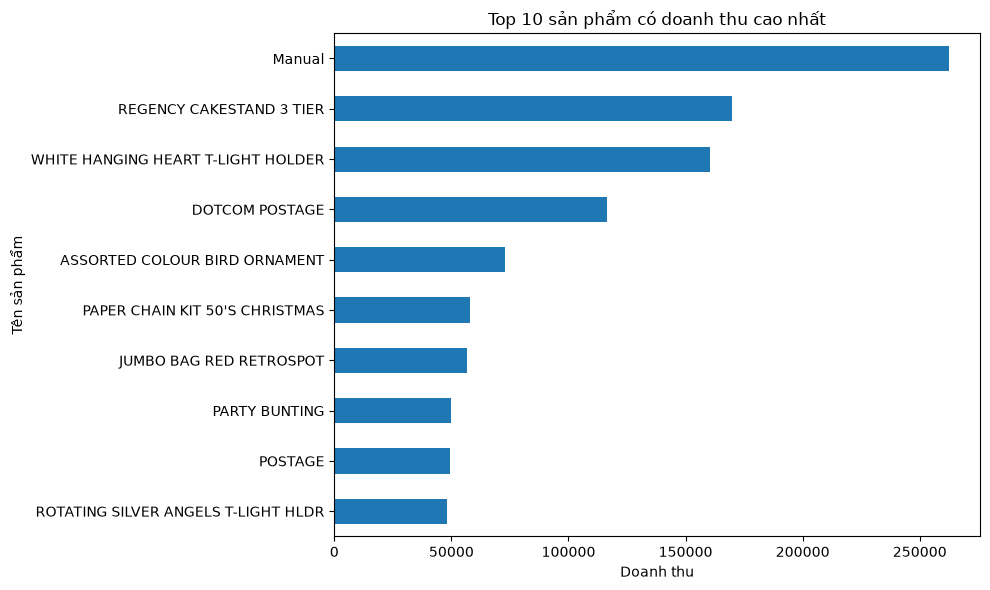

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 sản phẩm có doanh thu cao nhất")
plt.xlabel("Doanh thu")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()

In [22]:
top_countries = (
    df_sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 quốc gia theo doanh thu:")
display(top_countries.reset_index())

Top 10 quốc gia theo doanh thu:


,Country,Revenue
0,United Kingdom,8812311.833
1,EIRE,380909.570
2,Netherlands,268784.350
3,Germany,202025.391
4,France,147103.140
5,Sweden,53501.990
6,Denmark,50906.850
7,Spain,47568.650
8,Switzerland,43921.390
9,Australia,31446.800


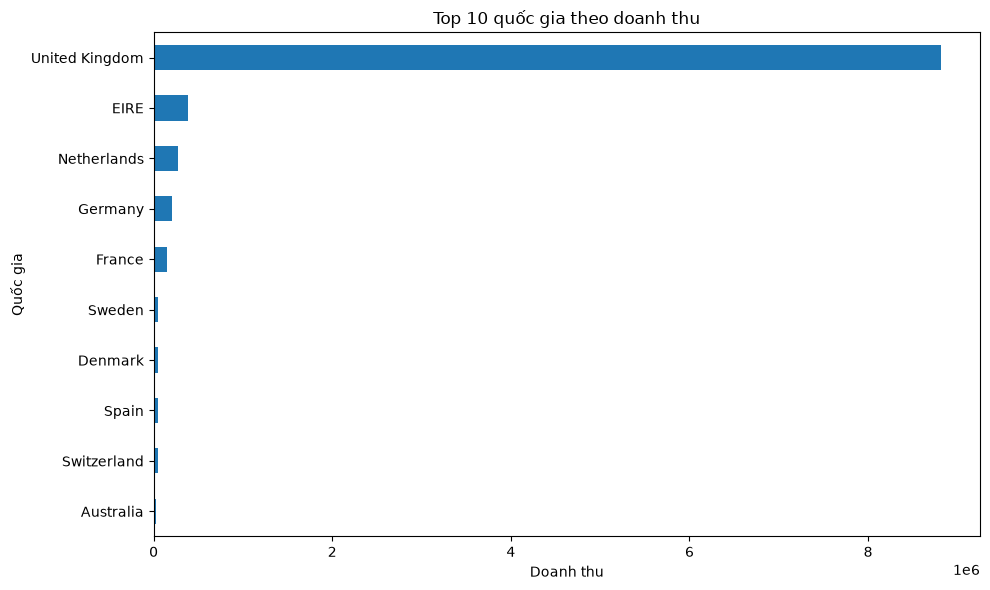

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 quốc gia theo doanh thu")
plt.xlabel("Doanh thu")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

In [24]:
country_orders = (
    df_sales.groupby("Country")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 quốc gia có nhiều đơn hàng nhất:")
display(country_orders.reset_index())

Top 10 quốc gia có nhiều đơn hàng nhất:


,Country,Invoice
0,United Kingdom,19290
1,EIRE,348
2,Germany,347
3,France,241
4,Netherlands,135
5,Sweden,69
6,Spain,66
7,Belgium,52
8,Portugal,41
9,Switzerland,40


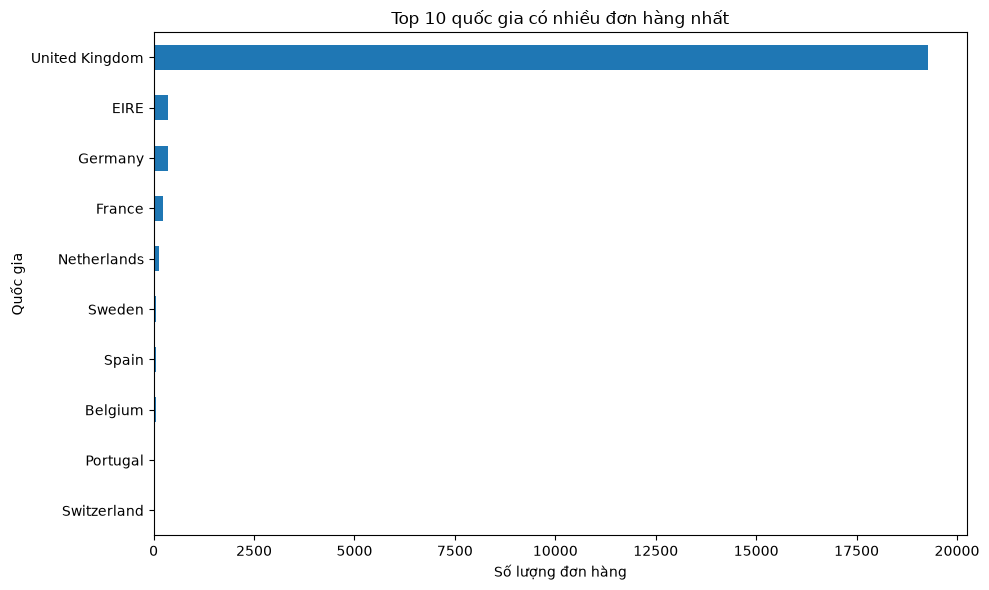

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
country_orders.sort_values().plot(kind="barh")

plt.title("Top 10 quốc gia có nhiều đơn hàng nhất")
plt.xlabel("Số lượng đơn hàng")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

In [ ]:
1top_quantity = (
    df_sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 sản phẩm bán chạy nhất theo số lượng:")
display(top_quantity.reset_index())

Top 10 sản phẩm bán chạy nhất theo số lượng:


,Description,Quantity
0,WHITE HANGING HEART T-LIGHT HOLDER,58691
1,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54947
2,BROCADE RING PURSE,48374
3,PACK OF 72 RETRO SPOT CAKE CASES,46728
4,ASSORTED COLOUR BIRD ORNAMENT,45228
5,60 TEATIME FAIRY CAKE CASES,36348
6,PACK OF 60 PINK PAISLEY CAKE CASES,31805
7,JUMBO BAG RED RETROSPOT,30746
8,SMALL POPCORN HOLDER,29773
9,STRAWBERRY CERAMIC TRINKET BOX,27059


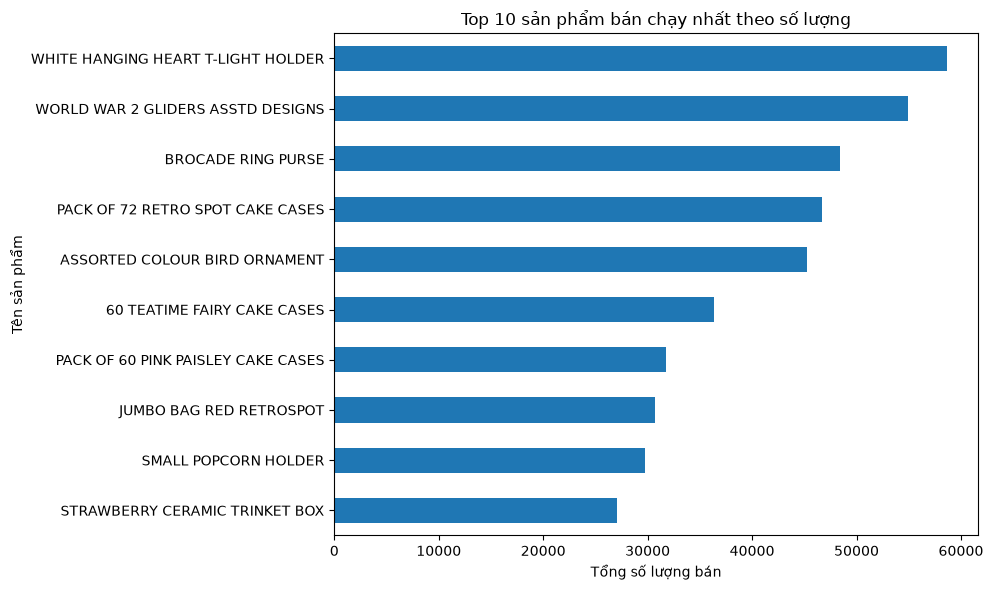

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_quantity.sort_values().plot(kind="barh")

plt.title("Top 10 sản phẩm bán chạy nhất theo số lượng")
plt.xlabel("Tổng số lượng bán")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()

In [28]:
df_daily = df_sales.copy()

df_daily["Date"] = (
    df_daily["InvoiceDate"].dt.normalize()
)

daily_revenue = (
    df_daily.groupby("Date")["Revenue"]
    .sum()
    .sort_index()
)

print("Số ngày có giao dịch:", len(daily_revenue))
print("Ngày đầu tiên:", daily_revenue.index.min())
print("Ngày cuối cùng:", daily_revenue.index.max())

display(daily_revenue.head())

Số ngày có giao dịch: 307
Ngày đầu tiên: 2009-12-01 00:00:00
Ngày cuối cùng: 2010-12-09 00:00:00


Date
2009-12-01    54351.23
2009-12-02    63172.58
2009-12-03    73972.45
2009-12-04    40582.32
2009-12-05     9803.05
Name: Revenue, dtype: float64

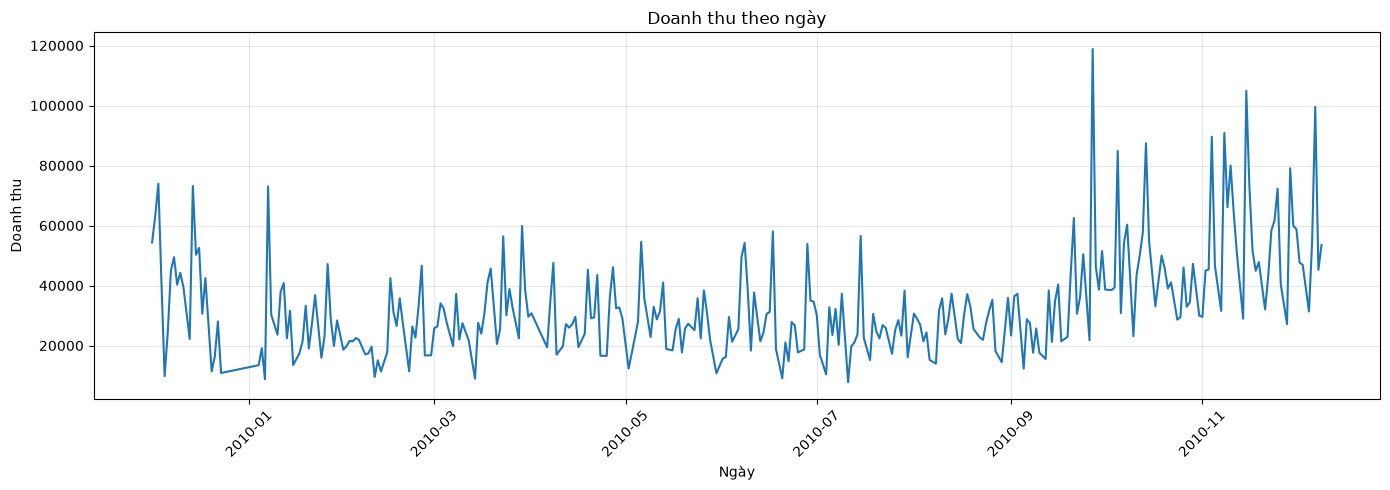

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_revenue.index,
    daily_revenue.values
)

plt.title("Doanh thu theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Doanh thu")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
df_regression = daily_revenue.reset_index()

df_regression["DayNumber"] = range(len(df_regression))

X = df_regression[["DayNumber"]]

y = df_regression["Revenue"]

print("Số mẫu dữ liệu:", len(df_regression))
print("\n5 dòng dữ liệu đầu tiên:")
display(df_regression.head())

Số mẫu dữ liệu: 307

5 dòng dữ liệu đầu tiên:


,Date,Revenue,DayNumber
0,2009-12-01,54351.23,0
1,2009-12-02,63172.58,1
2,2009-12-03,73972.45,2
3,2009-12-04,40582.32,3
4,2009-12-05,9803.05,4


In [31]:
split_index = int(len(df_regression) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

print("Ngày đầu tập kiểm tra:",
      df_regression["Date"].iloc[split_index])

print("Ngày cuối tập kiểm tra:",
      df_regression["Date"].iloc[-1])

Số mẫu huấn luyện: 245
Số mẫu kiểm tra: 62
Ngày đầu tập kiểm tra: 2010-09-29 00:00:00
Ngày cuối tập kiểm tra: 2010-12-09 00:00:00


In [32]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Hệ số góc (b):", model.coef_[0])
print("Hệ số chặn (a):", model.intercept_)

print(
    f"Phương trình hồi quy: Revenue = "
    f"{model.intercept_:.2f} + "
    f"({model.coef_[0]:.2f} * DayNumber)"
)

Hệ số góc (b): -5.836637108421954
Hệ số chặn (a): 29764.40973539074
Phương trình hồi quy: Revenue = 29764.41 + (-5.84 * DayNumber)


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

MAE: 22908.39
MSE: 868920905.9
RMSE: 29477.46
R²: -1.4672


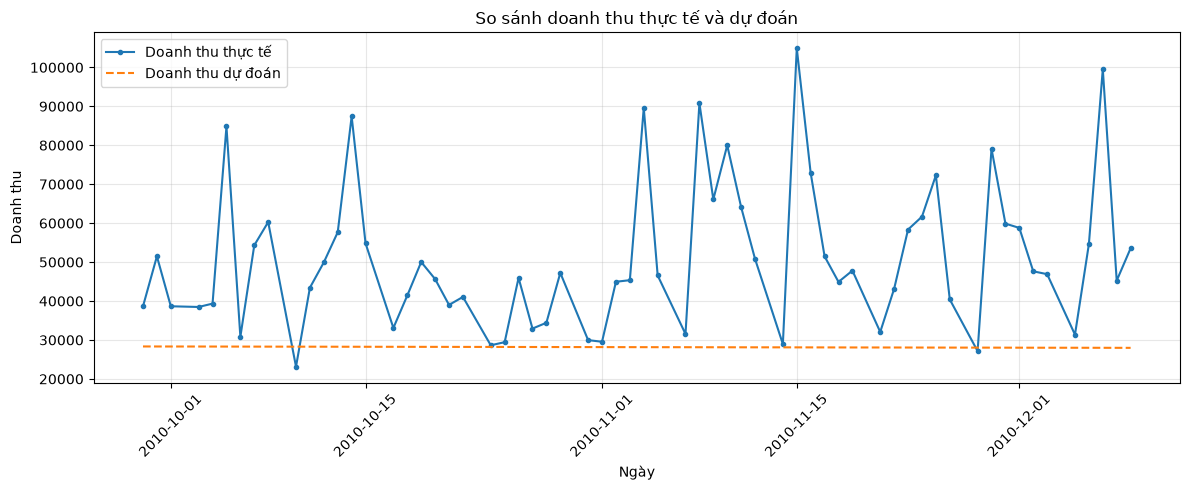

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_regression["Date"].iloc[split_index:],
    y_test.values,
    label="Doanh thu thực tế",
    marker="."
)

plt.plot(
    df_regression["Date"].iloc[split_index:],
    y_pred,
    label="Doanh thu dự đoán",
    linestyle="--"
)

plt.title("So sánh doanh thu thực tế và dự đoán")
plt.xlabel("Ngày")
plt.ylabel("Doanh thu")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()